# Lab 6

Prognostic models based on RNNs, LSTMs and GRUs  
By Alex Horyshevskyi  

### Installing dependencies

In [1]:
%pip install keras numpy polars scikit-image matplotlib albumentations --quiet
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### GPU check

In [2]:
import os

os.environ["KERAS_BACKEND"] = "torch"

In [3]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation will be performed on: {device}")

Using Keras version: 3.13.2
Using PyTorch version: 2.10.0+cu130
Computation will be performed on: cuda


### Importing libraries

In [4]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

from keras.models import Sequential
from keras.layers import (
    Input,
    LSTM,
    GRU,
    SimpleRNN,
    Dropout,
    Dense,
    RNN,
    LayerNormalization,
)
from keras.regularizers import L2
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam

## Case 1. Sinus wave proof of concept

### Generate & plot sinus wave data

In [5]:
start = -100
end = 100
step = 0.005

x = np.arange(start, end, step)
y_sin = np.sin(x)
y_sin_times_cos = np.sin(x) * np.cos(x)
y_tan_squared = np.tan(x) ** 2
y_tan_squared_clipped = np.clip(y_tan_squared, -10, 10)

dataframes = {
    "sin": pl.DataFrame({"y": y_sin}),
    "sin_times_cos": pl.DataFrame({"y": y_sin_times_cos}),
    "tan_squared_clipped": pl.DataFrame({"y": y_tan_squared_clipped}),
}

### Prepare data for the models

In [6]:
def load_data(
    stock: pl.DataFrame,
    seq_len: int,
    valid_set_size: float,
    test_set_size: float,
):
    data_raw = stock.to_numpy()
    data = []

    # create all possible sequences of length seq_len
    for index in range(len(data_raw) - seq_len):
        data.append(data_raw[index : index + seq_len])

    data = np.array(data)
    valid_set_size = int(np.round(valid_set_size * data.shape[0]))
    test_set_size = int(np.round(test_set_size * data.shape[0]))
    train_set_size = data.shape[0] - (valid_set_size + test_set_size)

    x_train = data[:train_set_size, :-1, :]
    y_train = data[:train_set_size, -1, :]
    x_valid = data[train_set_size : train_set_size + valid_set_size, :-1, :]
    y_valid = data[train_set_size : train_set_size + valid_set_size, -1, :]
    x_test = data[train_set_size + valid_set_size :, :-1, :]
    y_test = data[train_set_size + valid_set_size :, -1, :]
    return x_train, y_train, x_valid, y_valid, x_test, y_test

### Train the models

In [7]:
architectures: list[type[RNN]] = [LSTM, GRU, SimpleRNN]


def create_signal_model(
    architecture: type[RNN],
    shape: tuple[int, int],
    n_outputs: int,
    n_neurons: int = 200,
    n_layers: int = 2,
    activation: str = "elu",
    lr: float = 1e-3,
) -> Sequential:
    model = Sequential()
    model.add(Input(shape=shape))
    for i in range(n_layers):
        is_last = i == n_layers - 1
        model.add(
            architecture(n_neurons, activation=activation, return_sequences=not is_last)
        )
    model.add(Dense(n_outputs, activation="linear"))
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model


predictions = {}
seq_len = 20
batch_size = 2048

for dataset_name, df in dataframes.items():
    print(f"Processing {dataset_name} dataset...")
    X_train, y_train, X_valid, y_valid, X_test, y_test = load_data(
        df,
        seq_len=seq_len,
        valid_set_size=0.15,
        test_set_size=0.15,
    )
    predictions[dataset_name] = {}
    predictions[dataset_name]["true"] = y_test

    for arch in architectures:
        print(f"Training {arch.__name__} model...")
        model = create_signal_model(
            arch, 
            shape=(X_train.shape[1], X_train.shape[2]),
            n_outputs=y_train.shape[1]
        )
        history = model.fit(
            X_train,
            y_train,
            epochs=20,
            batch_size=batch_size,
            validation_data=(X_valid, y_valid),
            verbose=1,
        )
        loss = model.evaluate(X_test, y_test, verbose=0)

        stats = {
            "predictions": model.predict(X_test).flatten(),
            "train_loss": loss,
            "history": history.history,
        }
        predictions[dataset_name][arch.__name__] = stats
    
    print()

Processing sin dataset...
Training LSTM model...
Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - loss: 0.0796 - val_loss: 0.0012
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 0.0066 - val_loss: 0.0012
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0021 - val_loss: 0.0011
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 0.0011 - val_loss: 9.0094e-04
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 8.5930e-04 - val_loss: 7.9948e-04
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 7.6787e-04 - val_loss: 7.6119e-04
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 7.1636e-04 - val_loss: 7.1840e-04
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - loss: 6.6860e-04 - val_loss: 6.6659e-04
Epoch 9/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 6.2372e-04 - val_loss: 6.2240e-04
Epoch 10/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 5.7913e-04 - val_loss: 5.7338e-04
Epoch 11/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 93m

In [8]:
def plot_loss(
    history: dict[str, dict[str, list[float]]],
    arch_name: str,
    dataset_name: str,
    shift_val_loss_plot: bool = True,
):
    fig, axes = plt.subplots(1, len(history), figsize=(18, 5))
    for i, (arch_name, hist) in enumerate(history.items()):
        loss = hist.get("loss", [])
        val_loss = hist.get("val_loss", [])

        if shift_val_loss_plot:
            val_loss = [None] + val_loss

        axes[i].plot(loss, label=f"{arch_name} Train Loss")
        axes[i].plot(val_loss, label=f"{arch_name} Validation Loss")
        axes[i].set_title(f"{arch_name} Training and Validation Loss")
        axes[i].set_xlabel("Epochs")
        axes[i].set_ylabel("Loss")
        axes[i].legend()
    fig.suptitle(
        f"Training and Validation Loss for RNN Architectures on {dataset_name} Dataset",
        fontsize=16,
    )
    plt.tight_layout()
    plt.show()


def plot_predictions(
    predictions: dict[str, np.ndarray],
    limit: int = 200,
):
    y_true = predictions["true"]
    x_axis = np.arange(len(y_true))

    arch_preds = {k: v for k, v in predictions.items() if k != "true"}
    fig, axes = plt.subplots(1, len(arch_preds), figsize=(18, 5))

    for i, (arch_name, arch_data) in enumerate(arch_preds.items()):
        pred_values = arch_data["predictions"]
        axes[i].plot(
            x_axis[:limit],
            y_true[:limit],
            color="blue",
            label="True Values",
            alpha=0.5,
        )
        axes[i].plot(
            x_axis[:limit],
            pred_values[:limit],
            color="red",
            label="Predictions",
            alpha=0.5,
        )
        axes[i].set_title(f"{arch_name} Predictions")
        axes[i].set_xlabel("x")
        axes[i].set_ylabel("sin(x)")
        axes[i].legend()
    fig.suptitle(
        f"RNN Architectures Predictions vs True Values for {dataset_name} Dataset",
        fontsize=16,
    )
    plt.tight_layout()
    plt.show()


Plotting predictions for sin dataset...


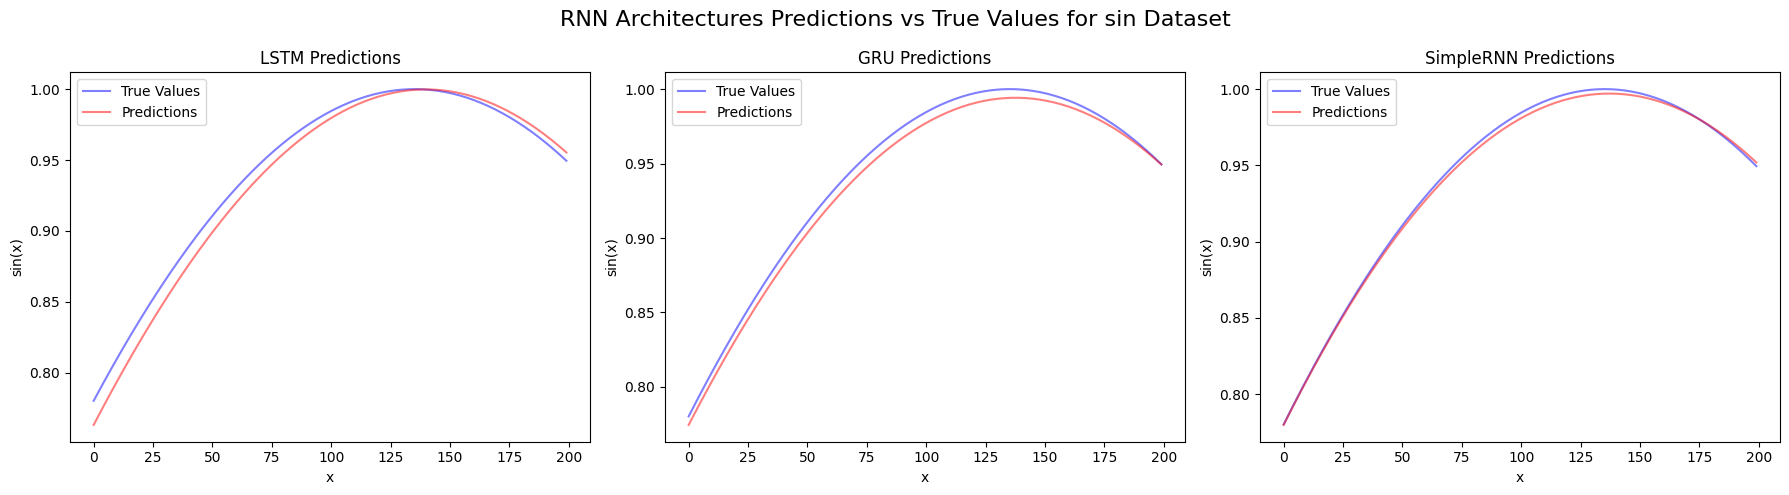

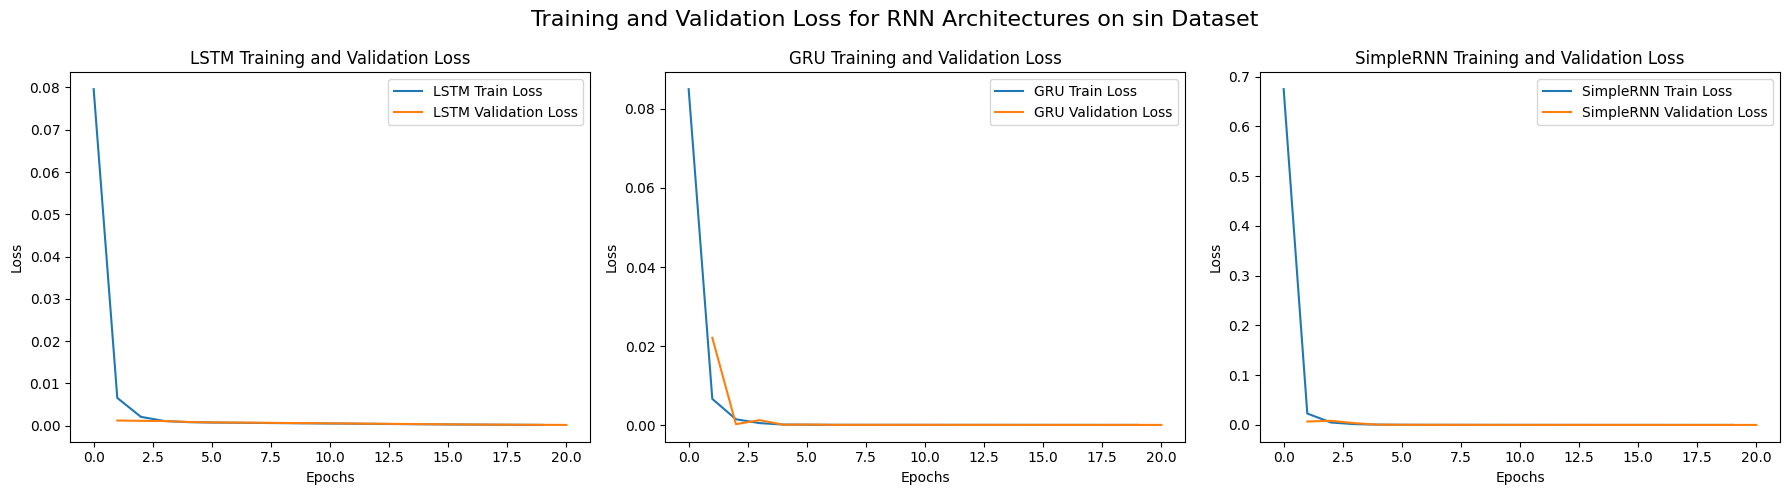


Plotting predictions for sin_times_cos dataset...


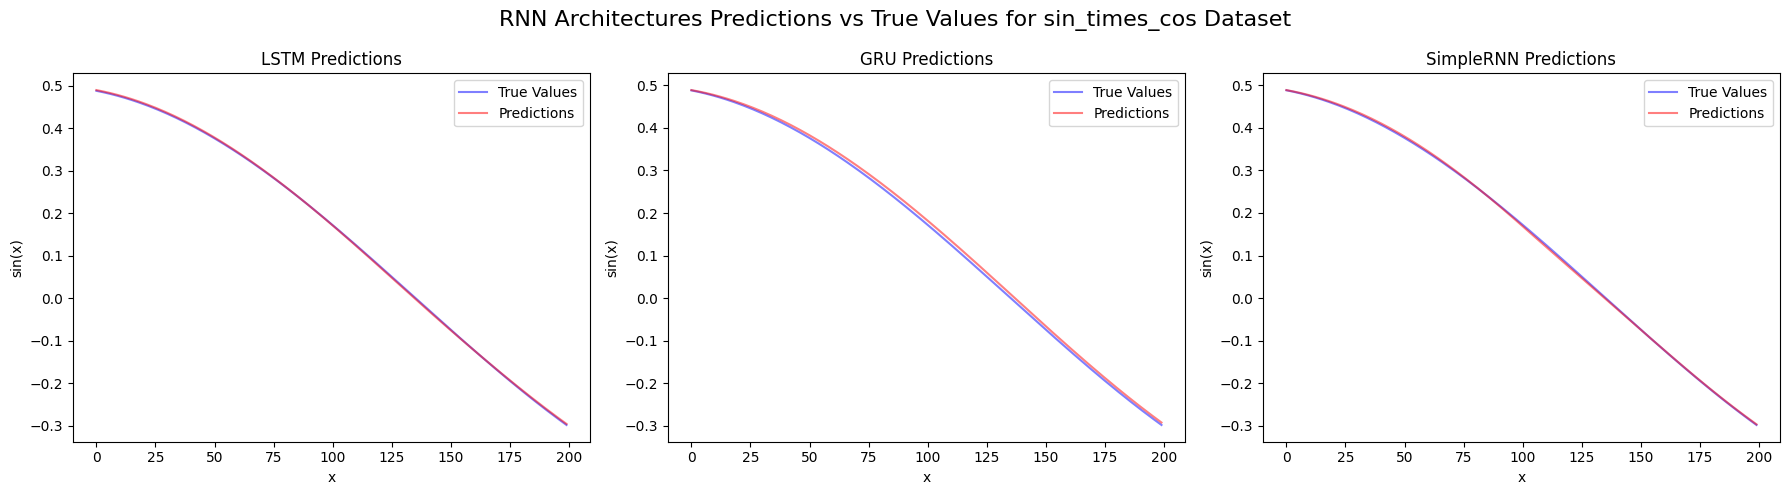

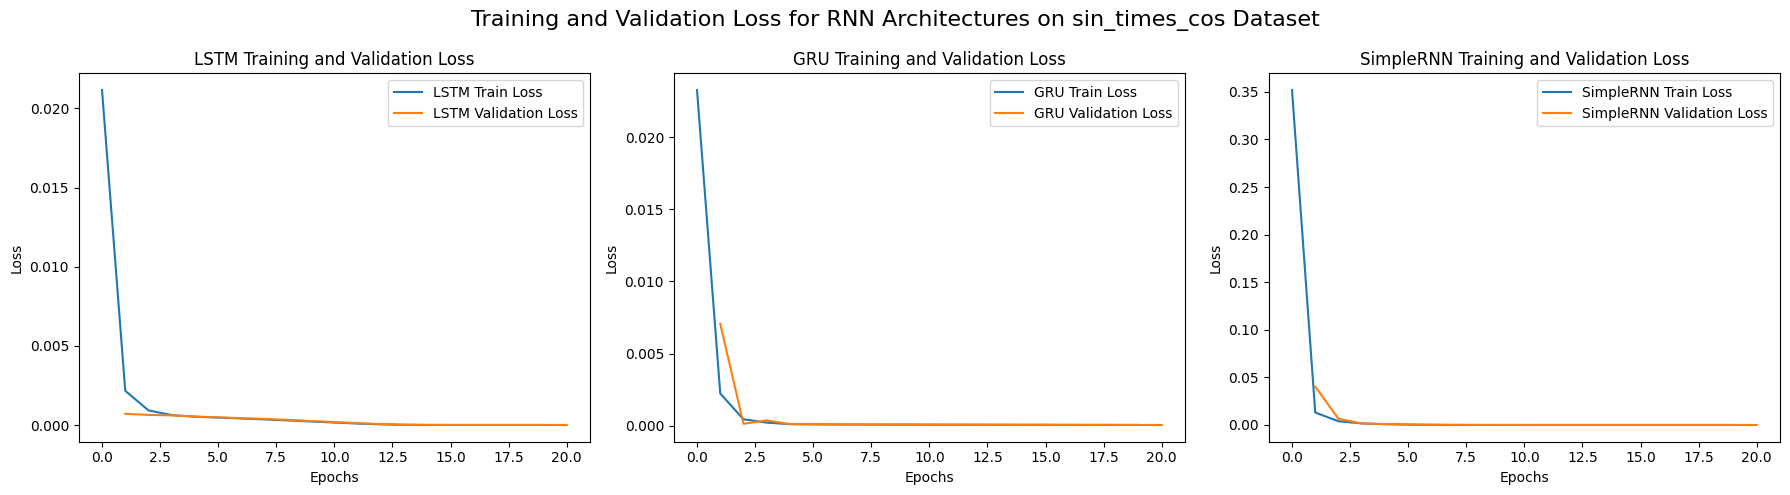


Plotting predictions for tan_squared_clipped dataset...


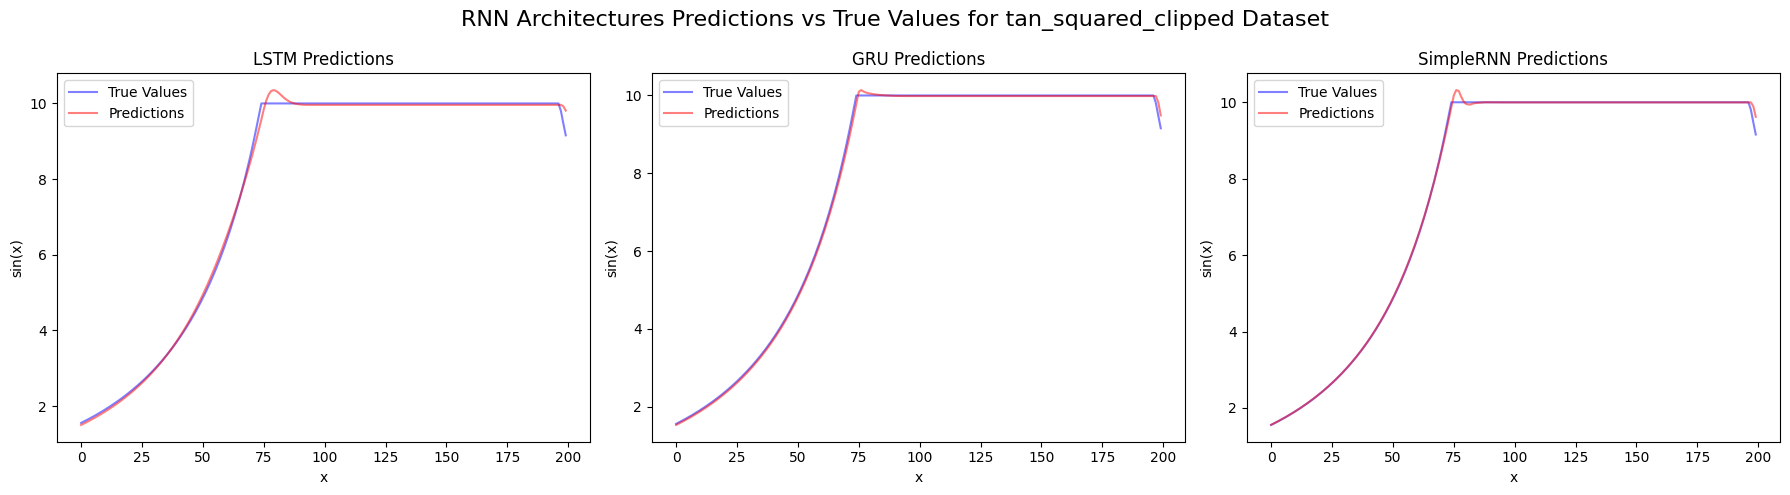

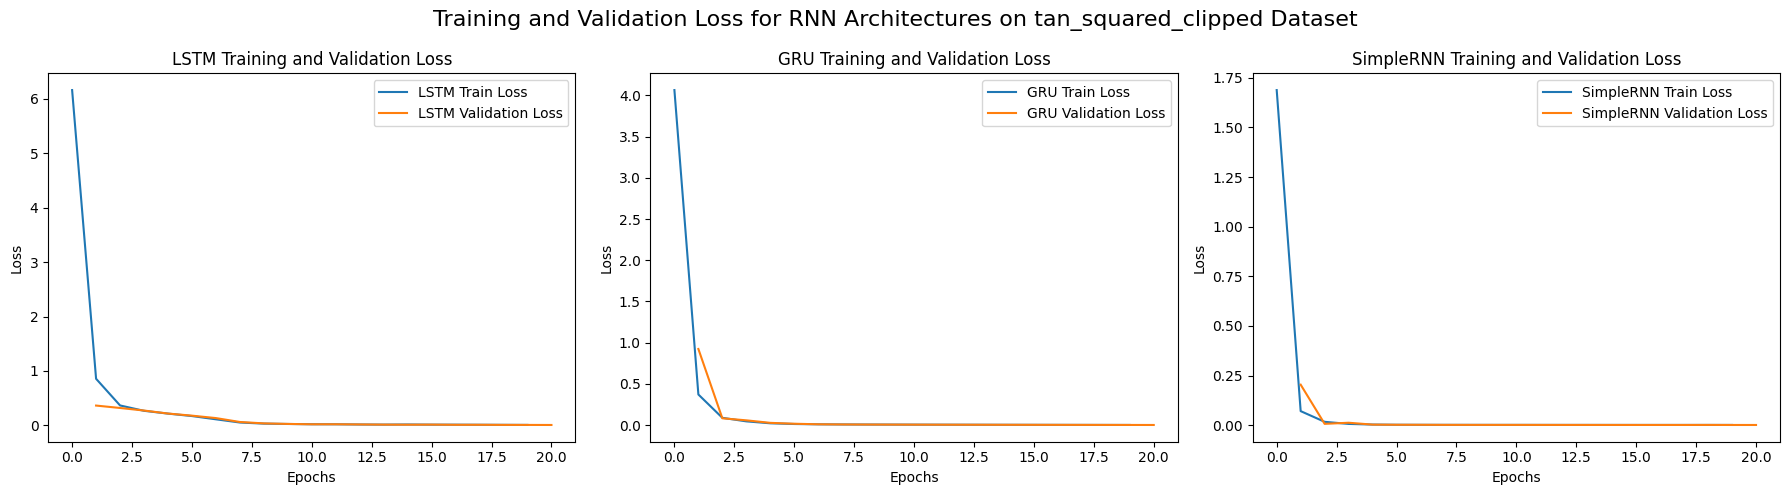

In [9]:
for dataset_name in dataframes.keys():
    print(f"\nPlotting predictions for {dataset_name} dataset...")
    plot_predictions(predictions[dataset_name])
    plot_loss(
        history={
            arch.__name__: predictions[dataset_name][arch.__name__]["history"]
            for arch in architectures
        },
        arch_name=dataset_name,
        dataset_name=dataset_name,
    )

## Case 2. NY Stock Price Prediction RNN LSTM GRU

### Prepare data for training

In [10]:
df = pl.read_csv("./prices-split-adjusted.csv")
single_stock_frame = df.filter(pl.col("symbol") == "EQIX")
print(df.head())

# number of different stocks
print("\nnumber of different stocks: ", df["symbol"].n_unique())
print(df["symbol"].unique().slice(0, 10).to_numpy())

shape: (5, 7)
┌────────────┬────────┬────────────┬────────────┬────────────┬────────────┬──────────┐
│ date       ┆ symbol ┆ open       ┆ close      ┆ low        ┆ high       ┆ volume   │
│ ---        ┆ ---    ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---      │
│ str        ┆ str    ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64      │
╞════════════╪════════╪════════════╪════════════╪════════════╪════════════╪══════════╡
│ 2016-01-05 ┆ WLTW   ┆ 123.43     ┆ 125.839996 ┆ 122.309998 ┆ 126.25     ┆ 2.1636e6 │
│ 2016-01-06 ┆ WLTW   ┆ 125.239998 ┆ 119.980003 ┆ 119.940002 ┆ 125.540001 ┆ 2.3864e6 │
│ 2016-01-07 ┆ WLTW   ┆ 116.379997 ┆ 114.949997 ┆ 114.93     ┆ 119.739998 ┆ 2.4895e6 │
│ 2016-01-08 ┆ WLTW   ┆ 115.480003 ┆ 116.620003 ┆ 113.5      ┆ 117.440002 ┆ 2.0063e6 │
│ 2016-01-11 ┆ WLTW   ┆ 117.010002 ┆ 114.970001 ┆ 114.089996 ┆ 117.330002 ┆ 1.4086e6 │
└────────────┴────────┴────────────┴────────────┴────────────┴────────────┴──────────┘

number of different stocks: 

In [11]:
print(df.describe())

shape: (9, 8)
┌────────────┬────────────┬────────┬────────────┬────────────┬────────────┬────────────┬───────────┐
│ statistic  ┆ date       ┆ symbol ┆ open       ┆ close      ┆ low        ┆ high       ┆ volume    │
│ ---        ┆ ---        ┆ ---    ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---       │
│ str        ┆ str        ┆ str    ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64       │
╞════════════╪════════════╪════════╪════════════╪════════════╪════════════╪════════════╪═══════════╡
│ count      ┆ 851264     ┆ 851264 ┆ 851264.0   ┆ 851264.0   ┆ 851264.0   ┆ 851264.0   ┆ 851264.0  │
│ null_count ┆ 0          ┆ 0      ┆ 0.0        ┆ 0.0        ┆ 0.0        ┆ 0.0        ┆ 0.0       │
│ mean       ┆ null       ┆ null   ┆ 64.993618  ┆ 65.011913  ┆ 64.336541  ┆ 65.639748  ┆ 5.4151e6  │
│ std        ┆ null       ┆ null   ┆ 75.203893  ┆ 75.201216  ┆ 74.459518  ┆ 75.906861  ┆ 1.2495e7  │
│ min        ┆ 2010-01-04 ┆ A      ┆ 1.66       ┆ 1.59       ┆ 1.5        ┆ 1

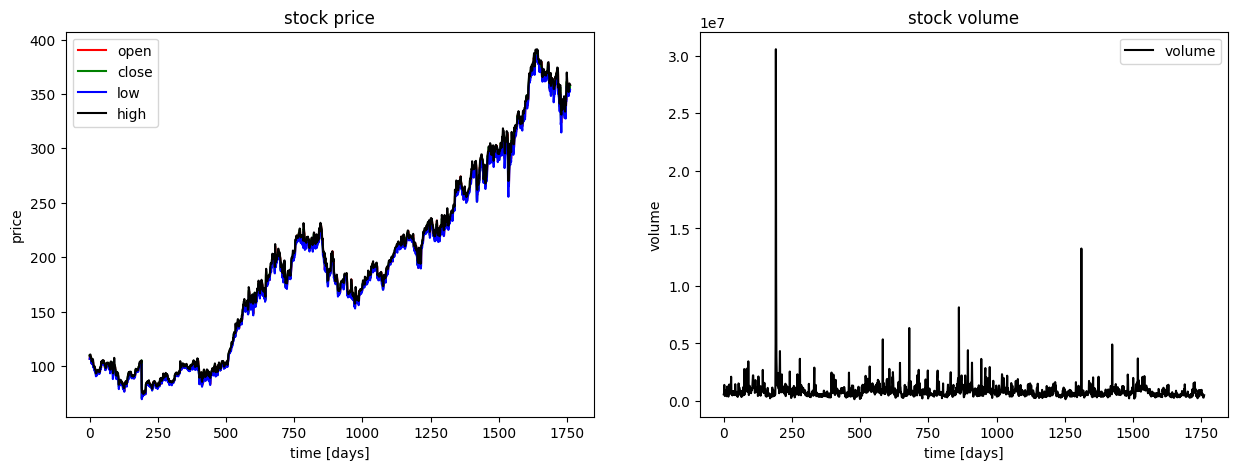

In [12]:
# visualize the stock price and volume for one of the stocks
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)

plt.plot(single_stock_frame.select("open"), color="red", label="open")
plt.plot(single_stock_frame.select("close"), color="green", label="close")
plt.plot(single_stock_frame.select("low"), color="blue", label="low")
plt.plot(single_stock_frame.select("high"), color="black", label="high")
plt.title("stock price")
plt.xlabel("time [days]")
plt.ylabel("price")
plt.legend(loc="best")

plt.subplot(1, 2, 2)
plt.plot(single_stock_frame.select("volume"), color="black", label="volume")
plt.title("stock volume")
plt.xlabel("time [days]")
plt.ylabel("volume")
plt.legend(loc="best")

plt.show()

X_train shape: (1191, 60, 5), y_train shape: (1191, 4)
X_valid shape: (255, 60, 5), y_valid shape: (255, 4)
X_test shape:  (255, 60, 5),  y_test shape:  (255, 4)
y_train range: [-33.07, 13.25]


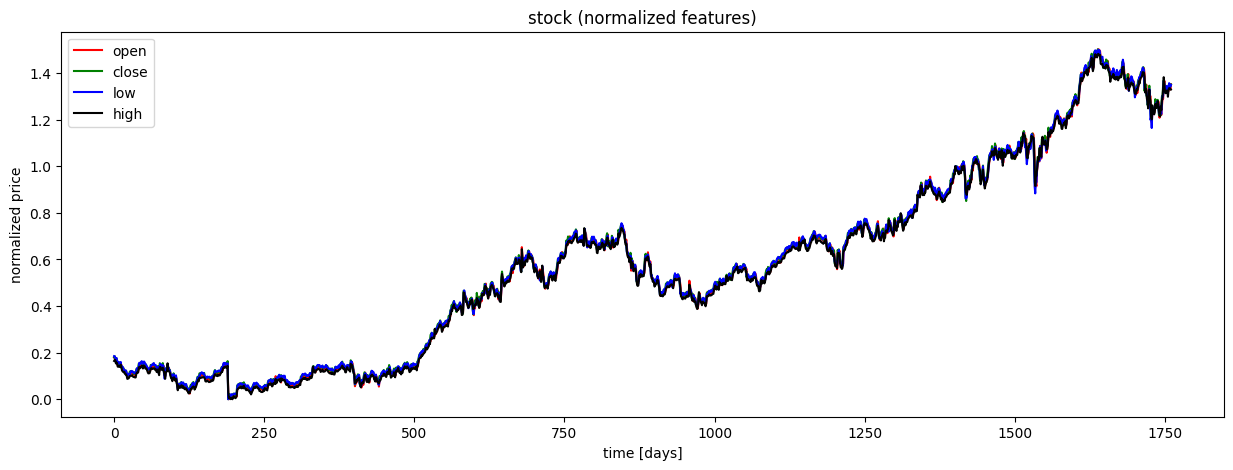

In [13]:
def normalize_data(
    df: pl.DataFrame, feature_cols: list[str], target_col: str, train_size: float = 0.8
):
    # Removes huge spikes on target column
    df = df.with_columns(pl.col("volume").log1p().alias("volume"))

    cols = list(dict.fromkeys(feature_cols + [target_col]))
    data = df.select(cols).to_numpy()

    # Split BEFORE fitting to prevent Data Leakage
    split_idx = int(len(data) * train_size)
    train_data = data[:split_idx]

    scaler = MinMaxScaler()
    scaler.fit(train_data)
    data_scaled = scaler.transform(data)

    df_scaled = pl.DataFrame(data_scaled, schema=cols)

    return df_scaled, scaler


def load_data_split(
    df: pl.DataFrame,
    feature_cols: list[str],
    target_cols: list[str],
    seq_len: int,
    valid_pct: float,
    test_pct: float,
    days_ahead: int = 1,
):
    features = df.select(feature_cols).to_numpy()
    targets = df.select(target_cols).to_numpy()

    X, y = [], []
    for i in range(len(features) - seq_len - days_ahead + 1):
        X.append(features[i : i + seq_len])
        future = targets[i + seq_len : i + seq_len + days_ahead]
        cum_return = np.prod(1 + future, axis=0) - 1
        y.append(cum_return)
    X, y = np.array(X), np.array(y)

    n = len(X)
    nv = int(round(valid_pct * n))  # Num validation samples
    nt = int(round(test_pct * n))   # Num test samples
    ntr = n - nv - nt               # Num training samples

    return (
        X[:ntr],
        y[:ntr],
        X[ntr : ntr + nv],
        y[ntr : ntr + nv],
        X[ntr + nv :],
        y[ntr + nv :],
    )


price_cols = ["open", "close", "low", "high"]
seq_len = 60

# Compute 1-day returns (targets) from RAW prices
returns_df = single_stock_frame.with_columns(
    [((pl.col(c) / pl.col(c).shift(1)) - 1.0).alias(f"{c}_return") for c in price_cols]
).drop_nulls()

# Normalize features on the aligned slice
df_stock_norm, _ = normalize_data(
    single_stock_frame.slice(1),
    feature_cols=["open", "close", "low", "high", "volume"],
    target_col="volume",
)

# Combine: normalized + raw momentum features + return targets
df_combined = df_stock_norm.hstack(
    returns_df.select([f"{c}_return" for c in price_cols])
)

feature_cols = ["open", "close", "low", "high", "volume"]
return_cols = [f"{c}_return" for c in price_cols]

X_train, y_train, X_valid, y_valid, X_test, y_test = load_data_split(
    df_combined,
    feature_cols=feature_cols,
    target_cols=return_cols,
    seq_len=seq_len,
    valid_pct=0.15,
    test_pct=0.15,
)

# Scale to ~[-10, 10] so gradients aren't microscopic (~0.001 → ~0.1)
y_train *= 100
y_valid *= 100
y_test *= 100

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_valid shape: {X_valid.shape}, y_valid shape: {y_valid.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")
print(f"y_train range: [{y_train.min():.2f}, {y_train.max():.2f}]")

# Plot normalized feature values
plt.figure(figsize=(15, 5))
plt.plot(df_stock_norm["open"], color="red", label="open")
plt.plot(df_stock_norm["close"], color="green", label="close")
plt.plot(df_stock_norm["low"], color="blue", label="low")
plt.plot(df_stock_norm["high"], color="black", label="high")
plt.title("stock (normalized features)")
plt.xlabel("time [days]")
plt.ylabel("normalized price")
plt.legend(loc="best")
plt.show()

### Train the models

In [14]:
def construct_simple_model(
    arch: type[RNN], input_shape: tuple[int, int], output_units: int
) -> Sequential:
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(arch(64, return_sequences=True))
    model.add(Dropout(0.2))
    model.add(arch(32, return_sequences=False))
    model.add(Dropout(0.2))
    model.add(Dense(output_units, activation="linear"))
    model.compile(optimizer="adam", loss="mse")
    return model


def construct_tuned_model(arch, input_shape, output_units):
    model = Sequential()
    model.add(Input(shape=input_shape))
    
    model.add(arch(64, return_sequences=True, kernel_regularizer=L2(1e-4)))
    model.add(LayerNormalization())
    model.add(Dropout(0.3))
    
    model.add(arch(32, return_sequences=False, kernel_regularizer=L2(1e-4)))
    model.add(LayerNormalization())
    model.add(Dropout(0.3))
    
    model.add(Dense(16, activation="relu"))
    
    model.add(Dense(output_units, activation="linear"))
    
    model.compile(
        optimizer=Adam(learning_rate=5e-4, clipnorm=1.0), 
        loss="mse"
    )
    return model

In [15]:
arches = [LSTM, GRU, SimpleRNN]


def train_and_evaluate_model(
    construct_model,
    train: tuple[np.ndarray, np.ndarray],
    valid: tuple[np.ndarray, np.ndarray],
    test: tuple[np.ndarray, np.ndarray],
    batch_size: int,
    n_epochs: int,
):
    X_train, y_train = train
    X_valid, y_valid = valid
    X_test, _ = test
    
    n_steps = X_train.shape[1]
    n_inputs = X_train.shape[2]
    n_outputs = y_train.shape[1]

    results = {}

    for arch in arches:
        print(f"Training {arch.__name__} model...")

        model = construct_model(
            arch, input_shape=(n_steps, n_inputs), output_units=n_outputs
        )
        callbacks = [
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, verbose=0),
            EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ]

        history = model.fit(
            X_train,
            y_train,
            epochs=n_epochs,
            batch_size=batch_size,
            validation_data=(X_valid, y_valid),
            callbacks=callbacks,
            verbose=0,
        )

        results[arch.__name__] = {
            "mse_train": model.evaluate(X_train, y_train, verbose=0),
            "mse_valid": model.evaluate(X_valid, y_valid, verbose=0),
            "predictions": (
                model.predict(X_train),
                model.predict(X_valid),
                model.predict(X_test),
            ),
            "history": history.history,
        }

        print()

    return results

In [16]:
# parameters
batch_size = 512
n_epochs = 100

args = {
    "train": (X_train, y_train),
    "valid": (X_valid, y_valid),
    "test": (X_test, y_test),
    "batch_size": batch_size,
    "n_epochs": n_epochs,
}

all_results_1d = {
    "Simple model": train_and_evaluate_model(construct_simple_model, **args),
    "Tuned model": train_and_evaluate_model(construct_tuned_model, **args),
}

Training LSTM model...
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step

Training GRU model...
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step

Training SimpleRNN model...
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

Training LSTM model...
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step

Training GRU model...
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step

Training SimpleRNN model...
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step



### Plotting the results


In [17]:
def to_2d(arr: np.ndarray) -> np.ndarray:
    return arr.reshape(-1, 1) if arr.ndim == 1 else arr


def sign_acc(true: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(np.sign(true) == np.sign(pred))


def plot_predictions(
    y_train: np.ndarray,
    y_valid: np.ndarray,
    y_test: np.ndarray,
    architectures: list[type[RNN]],
    predictions: dict[str, np.ndarray],
    ft: int = 0,
    suptitle: str = "Stock Return Prediction",
    shift: int = 0,
):
    """
    Plot true vs predicted returns for train, valid, and test sets.

    Args:
        y_train/y_valid/y_test: true return values (×100, %)
        predictions: dict with "predictions" key → (y_train_pred, y_valid_pred, y_test_pred)
        ft: return index to plot (0=open, 1=close, 2=low, 3=high)
        suptitle: overall figure title
        shift: number of days to shift the predictions
    """

    fig, axes = plt.subplots(1, len(architectures), figsize=(21, 6))
    fig.suptitle(suptitle, fontsize=16)

    for i, arch in enumerate(architectures):
        y_train_pred, y_valid_pred, y_test_pred = predictions[arch.__name__][
            "predictions"
        ]

        y_train, y_valid, y_test = map(to_2d, [y_train, y_valid, y_test])
        y_train_pred, y_valid_pred, y_test_pred = map(
            to_2d, [y_train_pred, y_valid_pred, y_test_pred]
        )

        ft = max(min(ft, y_train.shape[1] - 1), 0)

        n_train = y_train.shape[0]
        n_valid = y_valid.shape[0]
        n_test = y_test.shape[0]

        # --- reconstructed close price ---
        close_raw = single_stock_frame["close"].to_numpy()

        # first test sample predicts the return AT index: 1 (drop_nulls) + seq_len + n_train + n_valid
        test_start_idx = 1 + seq_len + n_train + n_valid
        base = close_raw[test_start_idx : test_start_idx + n_test]

        # index of "close_return" in return_cols
        close_col = 1

        true_close = base * (1 + y_test[:, close_col] / 100)
        pred_close = base * (1 + y_test_pred[:, close_col] / 100)

        sign_accuracy = (
            "Sign accuracy (correct direction) train/valid/test: %.2f/%.2f/%.2f"
            % (
                sign_acc(y_train[:, ft], y_train_pred[:, ft]),
                sign_acc(y_valid[:, ft], y_valid_pred[:, ft]),
                sign_acc(y_test[:, ft], y_test_pred[:, ft]),
            )
        )

        ax = axes[i]
        ax.plot(
            np.concatenate((np.full(shift, np.nan), true_close)),
            color="black",
            label="Actual close",
        )
        ax.plot(pred_close, color="green", label="Predicted close")
        ax.set_title(f"Reconstructed close price – {arch.__name__}\n{sign_accuracy}")
        ax.set_xlabel("Time [days]")
        ax.set_ylabel("Price ($)")
        ax.legend()

    plt.tight_layout()
    plt.show()

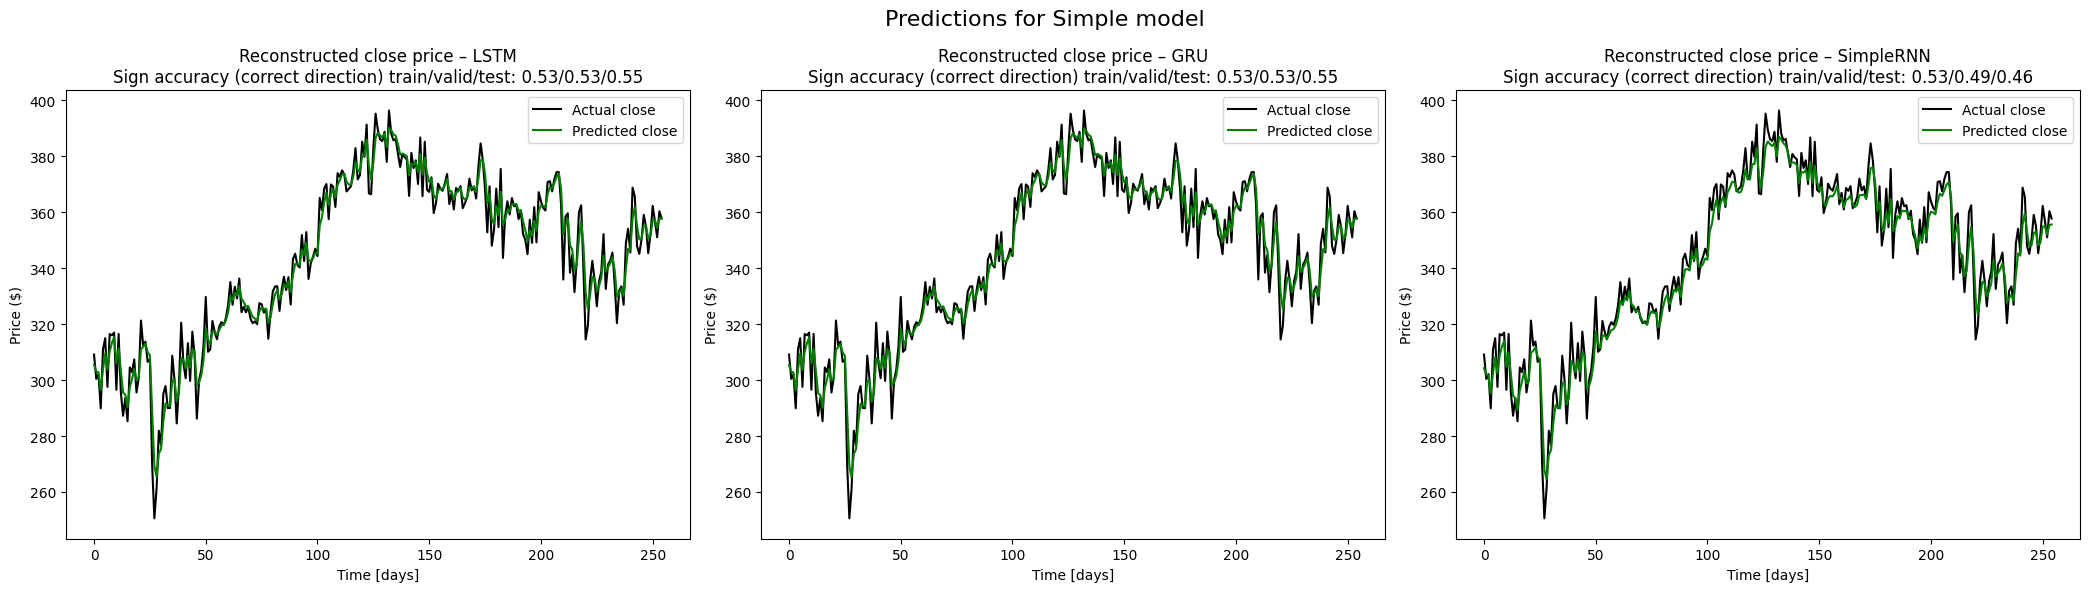

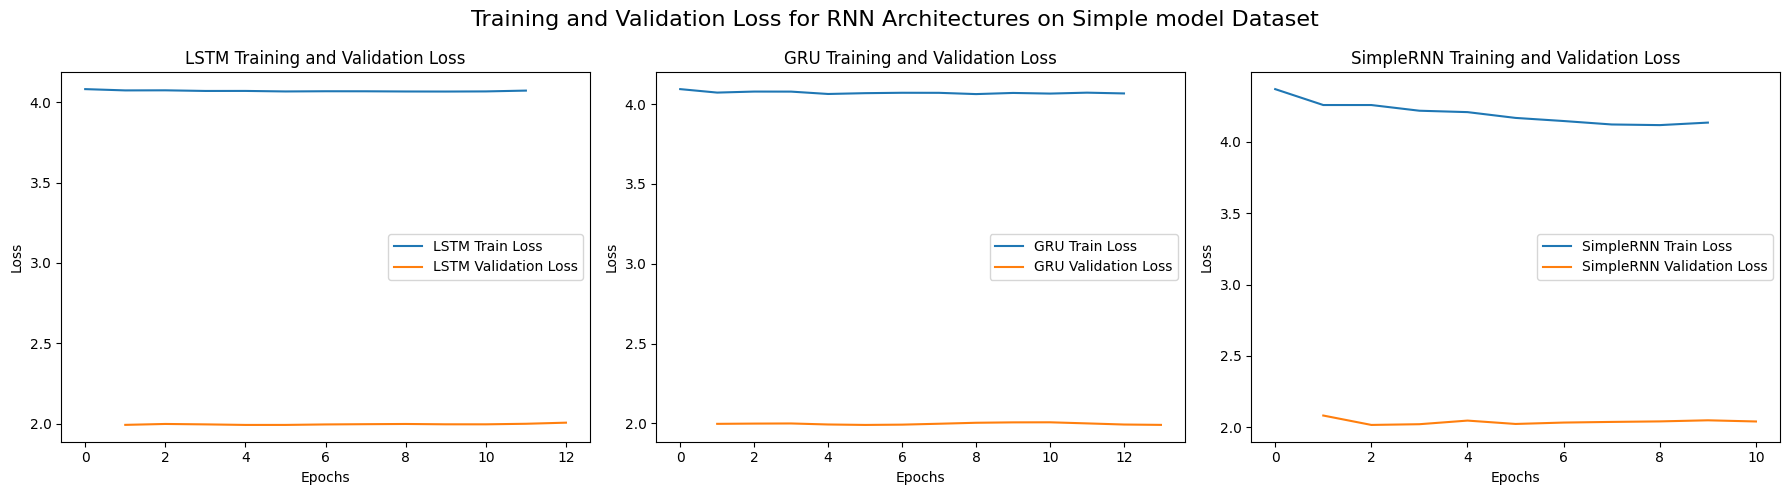

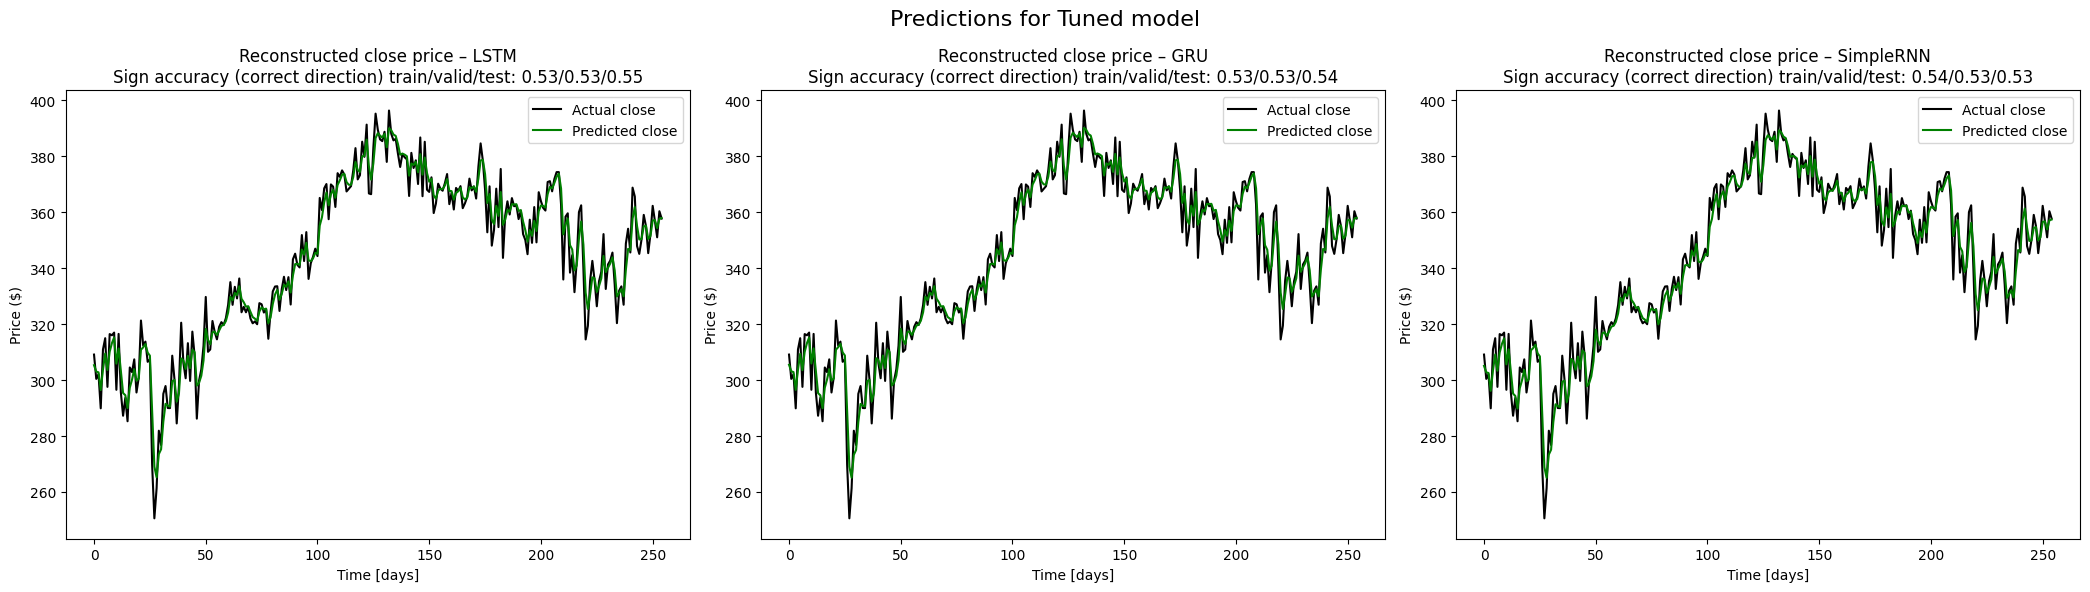

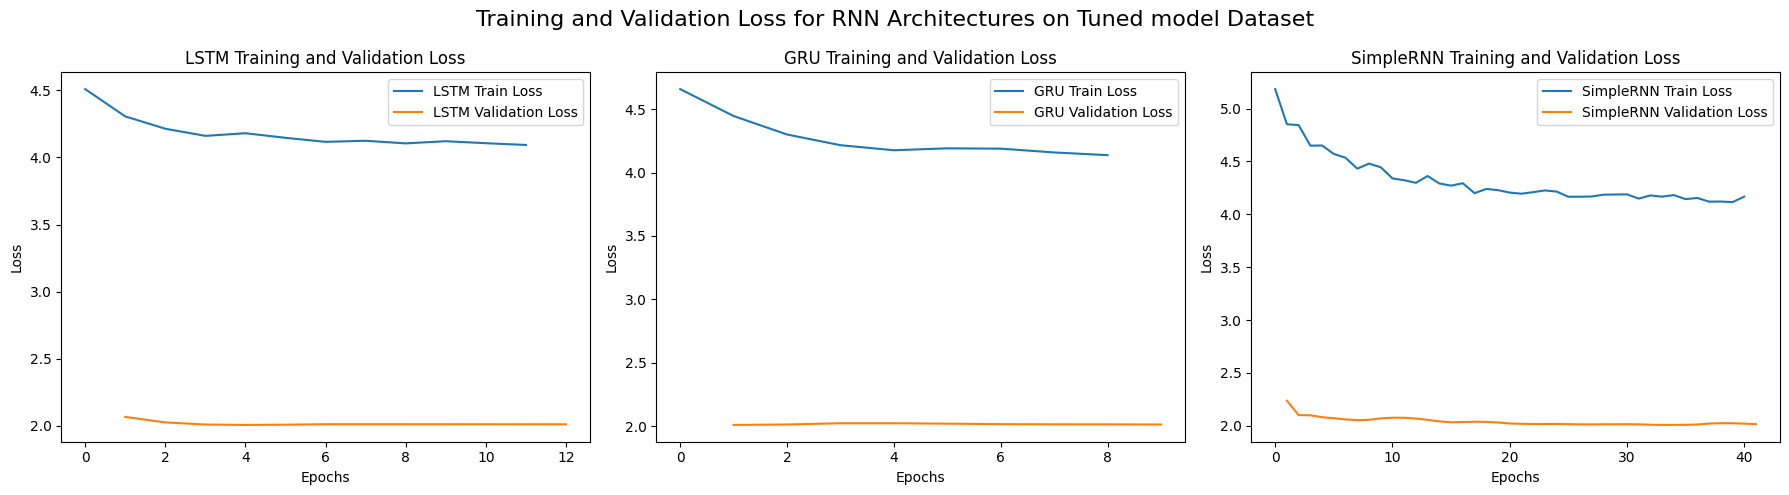

In [18]:
for title, results in all_results_1d.items():
    plot_predictions(
        y_train,
        y_valid,
        y_test,
        architectures,
        results,
        ft=1,  # close return
        suptitle=f"Predictions for {title}",
        shift=0  # shift predictions back by 1 day to align with true returns
    )
    plot_loss(
        history={
            arch.__name__: results[arch.__name__]["history"]
            for arch in architectures
        },
        arch_name=title,
        dataset_name=title,
    )

### Experiment: predict returns in 10 days instead of 1 day

In [19]:
days_ahead = 10
X_train, y_train, X_valid, y_valid, X_test, y_test = load_data_split(
    df_combined,
    feature_cols=feature_cols,
    target_cols=return_cols,
    seq_len=seq_len,
    valid_pct=0.15,
    test_pct=0.15,
    days_ahead=days_ahead,
)

# Scale to ~[-10, 10] so gradients aren't microscopic (~0.001 → ~0.1)
y_train *= 100
y_valid *= 100
y_test *= 100

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_valid shape: {X_valid.shape}, y_valid shape: {y_valid.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")
print(f"y_train range: [{y_train.min():.2f}, {y_train.max():.2f}]")

X_train shape: (1184, 60, 5), y_train shape: (1184, 4)
X_valid shape: (254, 60, 5), y_valid shape: (254, 4)
X_test shape:  (254, 60, 5),  y_test shape:  (254, 4)
y_train range: [-29.49, 15.75]


In [21]:
# parameters
batch_size = 512
n_epochs = 100

args = {
    "train": (X_train, y_train),
    "valid": (X_valid, y_valid),
    "test": (X_test, y_test),
    "batch_size": batch_size,
    "n_epochs": n_epochs,
}

all_results_10d = {
    "Simple model (10d)": train_and_evaluate_model(
        construct_simple_model,
        **args,
    ),
    "Tuned model (10d)": train_and_evaluate_model(
        construct_tuned_model,
        **args,
    ),
}

Training LSTM model...
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step

Training GRU model...
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step

Training SimpleRNN model...
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

Training LSTM model...
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 100ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step

Training GRU model...
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step

Training SimpleRNN model...
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step



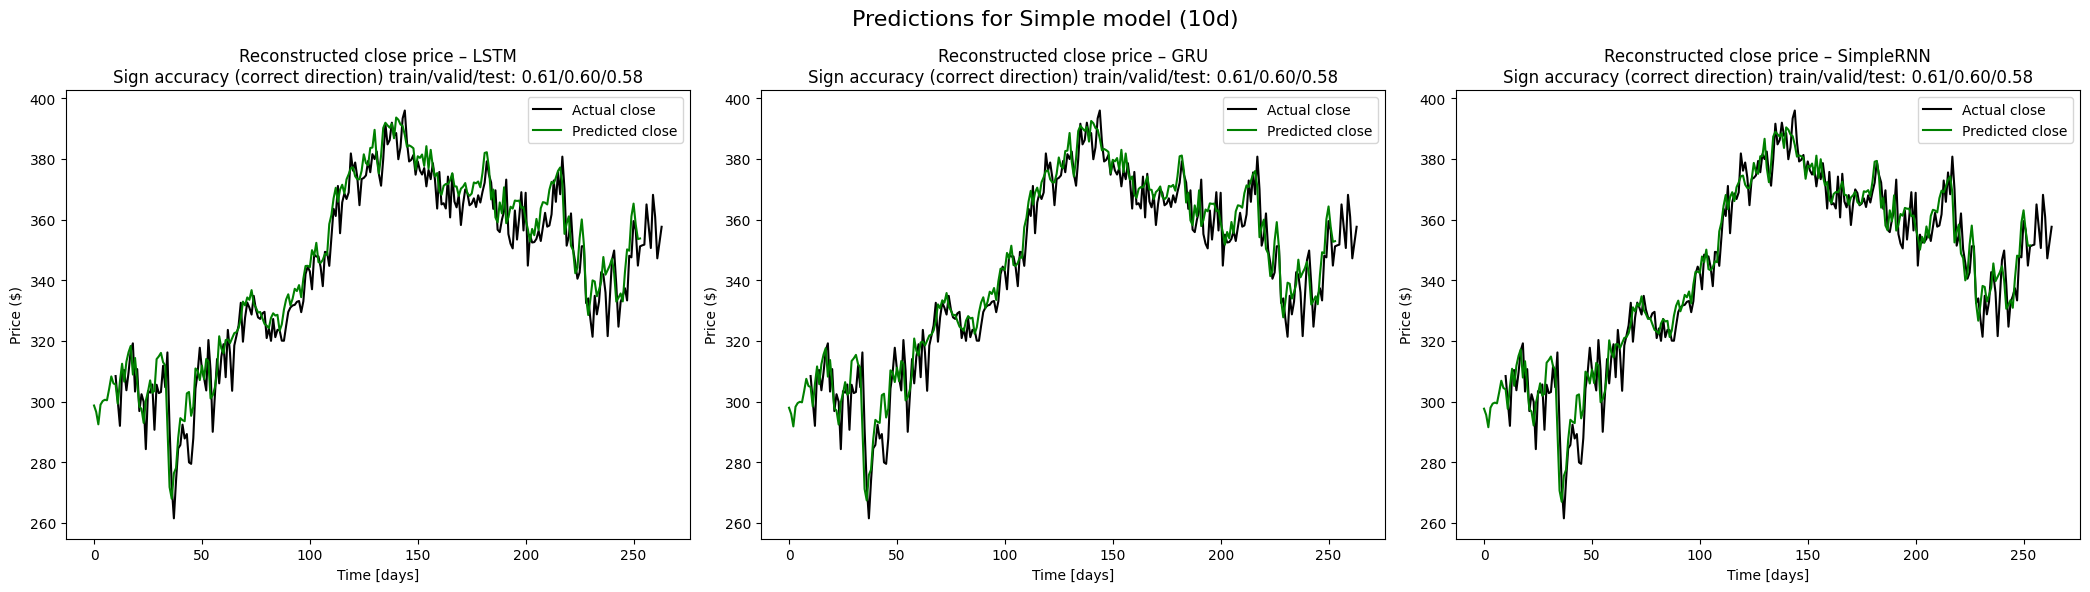

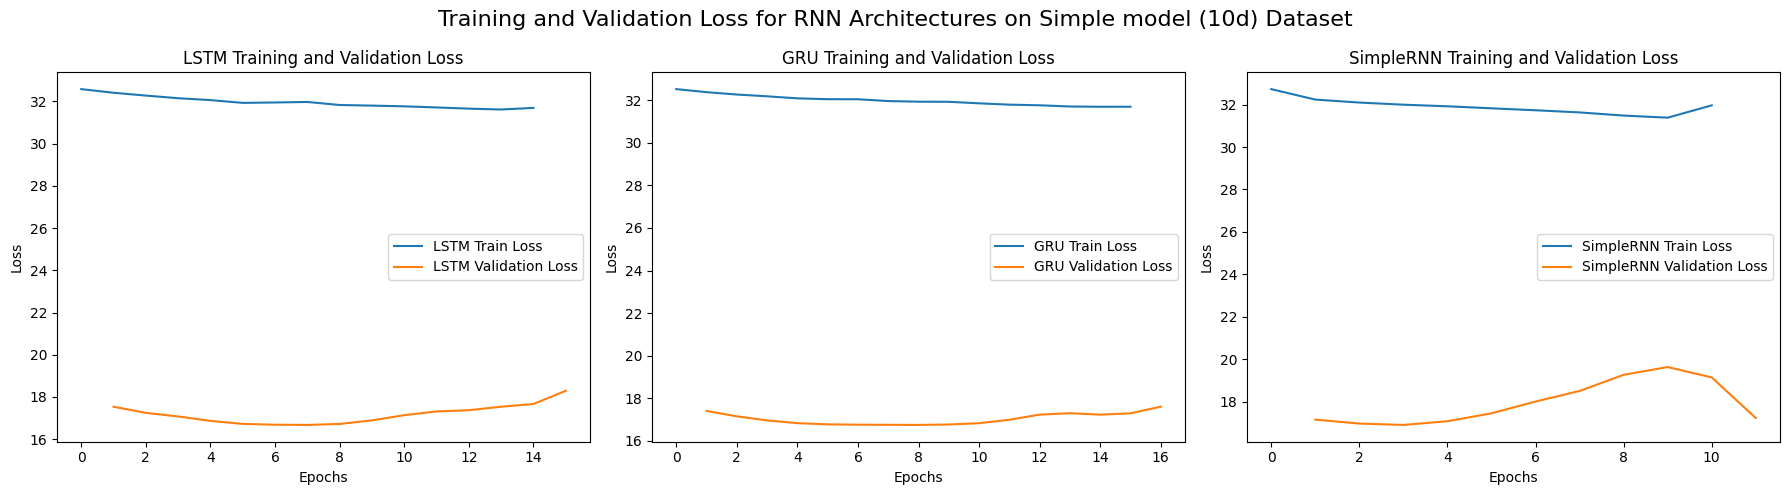

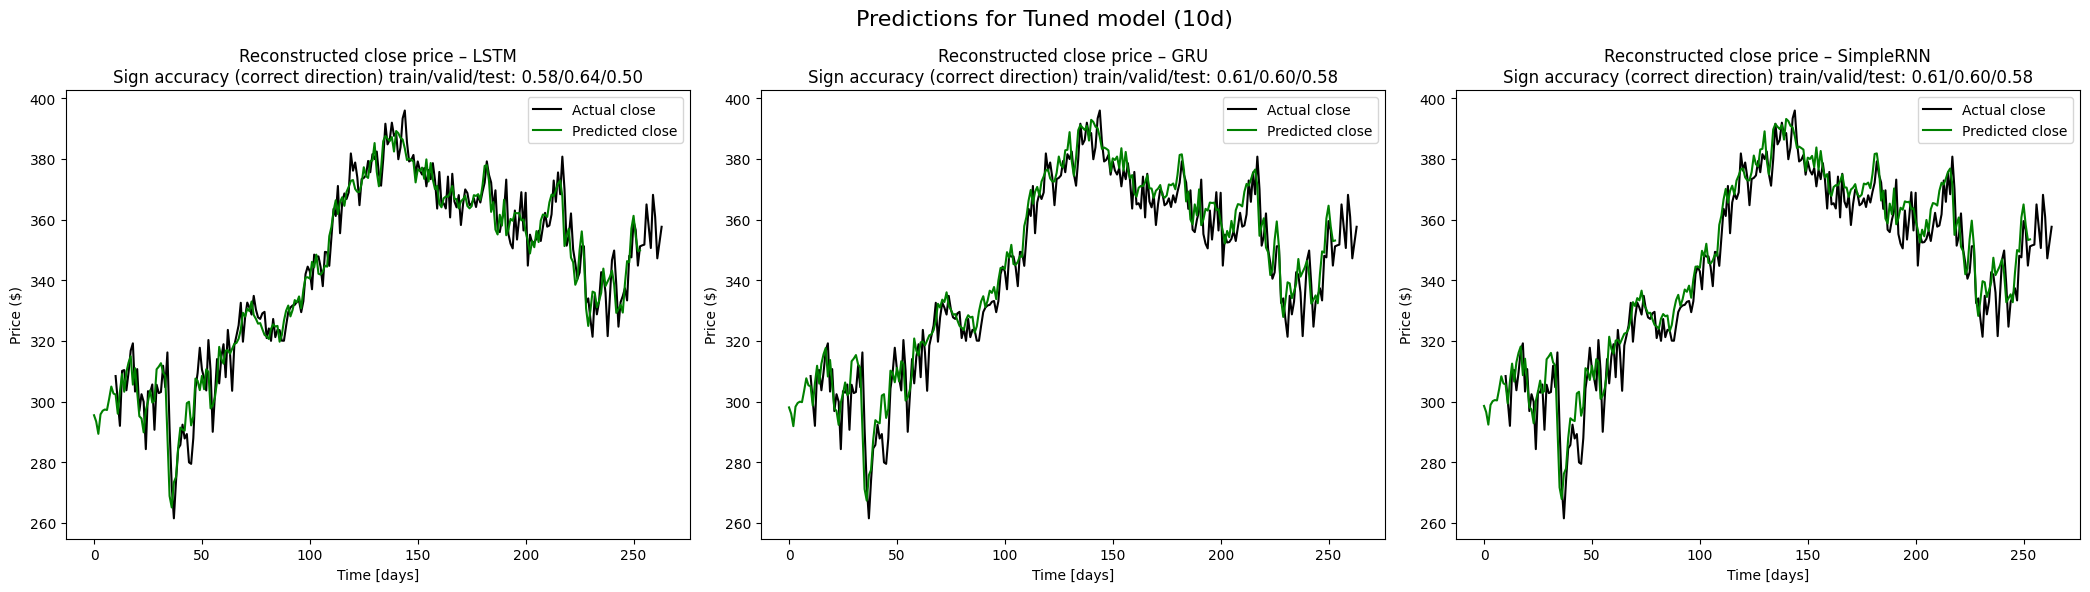

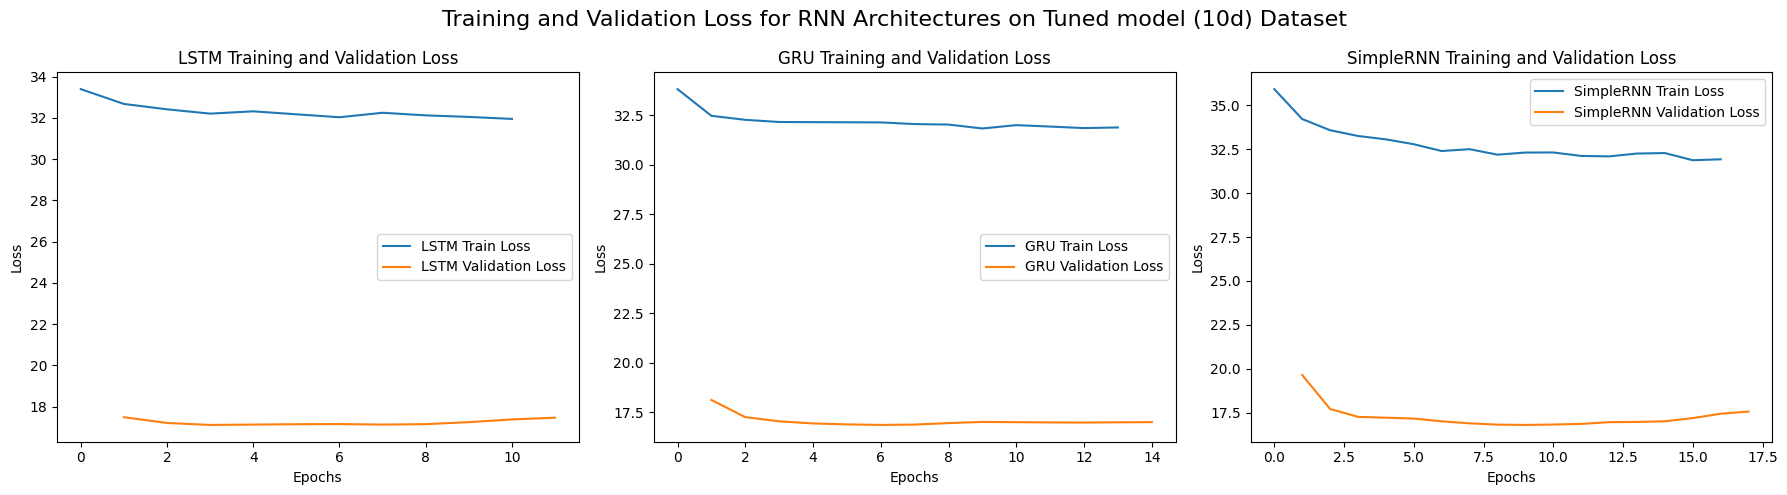

In [22]:
for title, results in all_results_10d.items():
    plot_predictions(
        y_train,
        y_valid,
        y_test,
        architectures,
        results,
        ft=1,  # close return
        suptitle=f"Predictions for {title}",
        shift=days_ahead
    )
    plot_loss(
        history={
            arch.__name__: results[arch.__name__]["history"]
            for arch in architectures
        },
        arch_name=title,
        dataset_name=title,
    )